# M2 基础验证（在原 Notebook 上修改）

**本次只运行第 3 节，运行到新增的 3.8 节后停止。第 4 节起是原 M1 内容，保留供参考。**

本次新增：对同一最终潜变量额外保存普通 VAE 图片，与官方最终 Control-VAE 输出比较。
默认 10 张真实生成图、原来的 E 代理；不新增训练。填写第 3.4 节权重路径和第 3.6 节图片路径。
先观察解码后有没有攻击成功变失败的案例，再决定是否修改 LAO 损失。

当前代码尚未在你们的 A100 和实际权重上运行；下面保留的 M1 结果不属于这次验证结果。

---
# StealthDiffusion: Reproduction and Baseline

**FIT5230 — Theme 1 (Adversarial ML on Generative AI), Dark side (attack / improvement)**
**Team:** `Dark.<TEAM_NAME>` — `<Member 1>`, `<Member 2>`

**Reference paper.** Z. Zhou, K. Sun, Z. Chen, H. Kuang, X. Sun, R. Ji.
*StealthDiffusion: Towards Evading Diffusion Forensic Detection through Diffusion Model.* ACM MM 2024. arXiv:2408.05669.
Official code: https://github.com/wyczzy/StealthDiffusion

---
### Abstract
Forensic detectors for AI-generated images rely heavily on an imperceptible **spectral fingerprint**
that generative decoders leave in the frequency domain. StealthDiffusion removes this fingerprint while
fooling the detector, by combining **Latent Adversarial Optimization (LAO)** with a **Control-VAE** module.
This notebook provides three things:

1. **Direct setup and execution of the official repository** (Section 3): we clone the authors' code,
   demonstrate that its 2023-era dependencies do not install on the current Colab Python, rebuild a
   compatible environment, load the released checkpoints, patch it for a single GPU, and launch the attack —
   reaching the point at which a free Colab **T4 (16 GB)** runs out of memory.
2. **A self-contained reproduction of the core mechanism** (Section 4), which executes end to end on a free
   Colab runtime. It builds a controlled genuine-vs-generated dataset, trains a forensic detector, applies
   gradient baselines (FGSM, PGD), and evaluates a **frequency-regularized attack** (our own increment, a
   pixel-space analogue of Control-VAE's spectral alignment).
3. **A report of the full-scale reproduction** (Section 5), executed on a local **RTX 4090 (24 GB)**, where
   the official pipeline completes and reaches the paper's reported detector-evasion ranges.

An interactive challenge for other teams is given in Section 6.

## 1. Problem statement
The task of **AI-Generated Content Stealth (AIGC-S)** is: given an AI-generated image, transform it so that
it evades a forensic detector while remaining visually unchanged. The difficulty is that adding adversarial
noise in pixel space (FGSM, PGD) can fool one specific detector but leaves the **spectral fingerprint**
intact, so the perturbation does not transfer to an unseen detector. Genuine stealth therefore requires
**aligning the image spectrum with that of real images without degrading quality**, which is the objective
that StealthDiffusion's Control-VAE addresses.

## 2. Reference method (StealthDiffusion)
StealthDiffusion has two components:

- **Latent Adversarial Optimization (LAO).** A light PGD preprocessing step injects an initial adversarial
  signal; the image is encoded into the latent space of Stable Diffusion, refined through a few
  noising/denoising steps, and the latent is optimized against a surrogate detector.
- **Control-VAE.** A trainable side-encoder is fused into the SD decoder through zero-initialized
  convolutions (a ControlNet-style connection). It is trained with a **Noise-Prototype Loss** that pulls the
  residual spectrum of generated images toward the averaged residual spectrum of genuine images, thereby
  erasing the fingerprint.

Section 3 sets up and runs the authors' official implementation; Section 4 reproduces the same idea at small
scale on free hardware; Section 5 reports the full-scale results from the official code.

## 3. 官方 StealthDiffusion：M2 基础小验证
沿用原 Notebook 的 Python 3.10 环境、六项权重和单 GPU 运行方式。
新增的代码在 **3.5 的末尾（保存普通 VAE 候选）**和 **3.7–3.8（比较结果）**。
每张图仍只运行一次官方攻击，两个输出来自最后一次潜变量更新之后的同一状态。


In [ ]:
# 3.1 下载官方代码。已有目录不会重置或覆盖。
from pathlib import Path
import subprocess

REPO = Path('/content/StealthDiffusion')
COMMIT = 'a156fb0792732e1aabc5b94a0cbecf6829e79d73'
if not REPO.exists():
    subprocess.run(['git', 'clone', 'https://github.com/wyczzy/StealthDiffusion.git', str(REPO)], check=True)
    subprocess.run(['git', '-C', str(REPO), 'checkout', '--detach', COMMIT], check=True)
actual = subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
if actual != COMMIT:
    raise RuntimeError('已有仓库版本不同，请使用一个新的 Colab 会话运行。')
%cd /content/StealthDiffusion


### 3.2 环境说明
直接沿用原 Notebook 的独立 Python 3.10 方案，跳过旧版依赖失败演示。


In [ ]:
print('下一格创建 /content/sdenv，后面的官方代码统一使用这个解释器。')


### 3.3 创建原有的 Python 3.10 环境
核心版本仍为 torch 2.2.2、diffusers 0.12.1、transformers 4.30.2。
首次运行需下载环境和模型。选择 A100 GPU；末尾逐项检查导入，并显示完整错误。
Colab 主环境可以是 Python 3.13，下面实际运行的独立环境必须是 Python 3.10。


In [ ]:
# 3.3 依赖安装：与原 Notebook 使用同一个 /content/sdenv 环境。
import shutil, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'uv'], check=True)
UV = shutil.which('uv')
PYTHON = '/content/sdenv/bin/python'
if not Path(PYTHON).exists():
    subprocess.run([UV, 'venv', '--python', '3.10', '/content/sdenv'], check=True)
subprocess.run([UV, 'pip', 'install', '--python', PYTHON,
                'torch==2.2.2', 'torchvision==0.17.2',
                '--index-url', 'https://download.pytorch.org/whl/cu121'], check=True)
packages = [
    'setuptools==80.9.0',  # 旧版 accelerate 需要其中的 pkg_resources；setuptools 82 起已移除。
    'numpy==1.26.4', 'diffusers==0.12.1', 'huggingface_hub==0.23.4',
    'transformers==4.30.2', 'accelerate==0.20.3', 'timm==0.6.12',
    'efficientnet-pytorch==0.7.1', 'torchattacks==3.5.1', 'lossers==0.0.9',
    'eagerpy==0.30.0', 'natsort==8.4.0', 'tensorboardX==2.6.2.2',
    'scipy==1.11.4', 'scikit-learn==1.3.2', 'opencv-python-headless==4.10.0.84',
    'Pillow==10.4.0', 'tqdm==4.66.1',
]
subprocess.run([UV, 'pip', 'install', '--python', PYTHON, *packages], check=True)
check = """
import sys
print('独立环境:', sys.executable, '| Python:', sys.version, flush=True)
if sys.version_info[:2] != (3, 10):
    raise RuntimeError('/content/sdenv 不是 Python 3.10，请将这行版本输出反馈给我们。')
print('[1/5] 导入 torch / torchvision', flush=True)
import torch, torchvision
print('torch:', torch.__version__, '| CUDA build:', torch.version.cuda, flush=True)
print('[2/5] 导入 diffusers / StableDiffusionPipeline', flush=True)
import diffusers
from diffusers import StableDiffusionPipeline
print('diffusers:', diffusers.__version__, flush=True)
print('[3/5] 导入 timm', flush=True)
import timm
print('timm:', timm.__version__, flush=True)
print('[4/5] 导入 lossers.lpips.LPIPS', flush=True)
from lossers.lpips import LPIPS
print('[5/5] 检查 CUDA GPU', flush=True)
if not torch.cuda.is_available():
    raise RuntimeError('此环境未检测到可用 CUDA GPU。请确认 Colab 已连接 GPU 运行时；若已经连接，请反馈上方 torch / CUDA build 信息。')
print('GPU:', torch.cuda.get_device_name(0), flush=True)
print('环境检查通过，可以继续运行 3.4。', flush=True)
"""
# 显式收集子进程输出，避免 Colab 只显示 CalledProcessError 而隐藏真正原因。
result = subprocess.run([PYTHON, '-u', '-c', check],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
print(result.stdout, flush=True)
if result.returncode != 0:
    raise RuntimeError('环境检查失败。完整报错已显示在上方，请先处理最后一条具体错误，再继续后面的单元格。')


### 3.4 Provide the pretrained weights and check readiness
The four detectors, Control-VAE, and the DnCNN residual extractor are the authors' checkpoints (distributed
separately from the code). Put the six files in a Google Drive folder and point `CKPT_SRC` at it; the cell
links them into `./checkpoints/` and prints a readiness table. This mirrors how the released code expects to
find them (`./checkpoints/*.pth`).

In [ ]:
#@title 3.4  Link checkpoints from Drive and verify
import os
CKPT_SRC = "/content/drive/MyDrive/StealthDiffusion/checkpoints"  #@param {type:"string"}
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
except Exception as e:
    print("drive mount skipped:", e)
os.makedirs("checkpoints", exist_ok=True)
need = ["efficientnet-b0.pth", "resnet50.pth", "deit.pth", "swin-t.pth", "Controlvae.pt", "dncnn_color_blind.pth"]
for f in need:
    s, d = os.path.join(CKPT_SRC, f), os.path.join("checkpoints", f)
    if os.path.exists(s) and not os.path.exists(d):
        try: os.symlink(s, d)
        except Exception: pass
print(f"{'checkpoint':<26}{'status':>9}")
ready = 0
for f in need:
    ok = os.path.exists(os.path.join("checkpoints", f)); ready += int(ok)
    print(f"{f:<26}{'READY' if ok else 'MISSING':>9}")
print(f"\n{ready}/6 checkpoints present" + ("" if ready == 6 else "  <- place the missing files in CKPT_SRC before running 3.6"))

### 3.5 单 GPU 兼容处理 + 新增观察
前半段保留原来的代理地址和 GPU 编号处理。后半段仅增加一次无梯度普通 VAE 解码，
保存 `*_plain_vae.png`。官方最终 Control-VAE 解码和 `*_adv_image.png` 保持原流程。


In [ ]:
#@title 3.5  Patch proxy / multi-GPU device ids
import re, pathlib
proxy_re = re.compile(r'^(\s*)(os\.environ\[["\']https?_proxy["\']\]\s*=)')
cvd_re   = re.compile(r'(CUDA_VISIBLE_DEVICES["\']\]\s*=\s*["\'])([1-9])(["\'])')
dev_re   = re.compile(r'cuda:([1-9])')
n = 0
for f in pathlib.Path(".").rglob("*.py"):
    out, changed = [], False
    for ln in f.read_text().splitlines(keepends=True):
        o = ln
        if proxy_re.match(ln) and not ln.lstrip().startswith("#"): ln = re.sub(proxy_re, r"\1# \2", ln)
        if cvd_re.search(ln): ln = cvd_re.sub(r"\g<1>0\g<3>", ln)
        if dev_re.search(ln): ln = dev_re.sub("cuda:0", ln)
        out.append(ln); changed = changed or (ln != o)
    if changed: f.write_text("".join(out)); n += 1
print("patched files:", n)

# M2 新增：最后一次 latent 更新后，在最终 Control-VAE 解码前保存普通候选。
attack_file = REPO / 'diff_latent_attack.py'
text = attack_file.read_text()
marker = '# M2_BASIC_PLAIN_VAE_OBSERVATION'
anchor = """    with torch.no_grad():
        latents = torch.cat([original_latent, latent])

        for ind, t in enumerate(model.scheduler.timesteps[1 + start_step - 1:]):
            latents = diffusion_step(model, latents, context[ind], t, guidance_scale)

    if args.is_encoder == 1:"""
observation = """    # M2_BASIC_PLAIN_VAE_OBSERVATION
    with torch.no_grad(), torch.random.fork_rng(devices=[torch.cuda.current_device()]):
        plain = model.vae.decode(1 / 0.18215 * latents.detach())['sample'][1:]
        plain = (plain / 2 + 0.5).clamp(0, 1)
        plain = denormalize(normalize(plain))
        pixels = np.uint8(plain.cpu().numpy()[0].transpose(1, 2, 0) * 255.)
        Image.fromarray(pixels).save(save_path + '_plain_vae.png')

"""
if marker not in text:
    if text.count(anchor) != 1:
        raise RuntimeError('没有找到唯一的最终潜变量位置，停止修改。')
    text = text.replace(anchor, anchor.replace('    if args.is_encoder == 1:', observation + '    if args.is_encoder == 1:'), 1)
    compile(text, str(attack_file), 'exec')
    attack_file.write_text(text)
print('M2 普通 VAE 观察已就绪；原攻击目标没有改变。')


### 3.6 运行少量真实生成图
**先准备输入数据。** [原论文第 4.1 节](https://arxiv.org/html/2408.05669v1#S4.SS1)
使用 GenImage，从 8 个来源的验证集各抽 100 张，共 800 张。
本轮建议先从 Stable Diffusion 1.4 或 1.5 的 `val/ai` 中抽 10 张。
[GenImage 官方说明](https://github.com/GenImage-Dataset/GenImage#dataset)提供
[Google Drive 下载入口](https://drive.google.com/drive/folders/1jGt10bwTbhEZuGXLyvrCuxOI0cBqQ1FS)。
注意：官方 SD 1.4/1.5 目录按分卷压缩包发布，分别约 96.4/101.7 GB；
当前没有核实到可单独下载的 10 张验证图小包，最后一个 `.zip` 也不是独立数据包。
下载并解压所选来源的数据后，将 `GENERATED_ROOT` 改成其 `val/ai` 的实际路径，
或把选出的原始图片放入下方指定目录。不能指向同时包含 `ai` 和 `nature` 的上级目录。
下方默认路径只是存放位置，不会自动下载图片；原 M1 也未附带那六张 SD 图片。
不使用随机 placeholder 或论文截图作为输入。默认 10 张，已有样本较少时可调小 `N_IMAGES`。
`SD_MODEL` 是攻击使用的 SD 2.1，与输入图片的生成来源分开记录。
E 是攻击代理，R/D/S 在后面仅做迁移观察。保持 10 次 LAO、DDIM20、最后 2 步、224 分辨率。


In [ ]:
# 3.6 只跑少量图片，不再创建随机占位图。
import json, random
from datetime import datetime
from PIL import Image

GENERATED_ROOT = '/content/drive/MyDrive/StealthDiffusion/sd_imgs' #@param {type:"string"}
N_IMAGES = 10 #@param {type:"integer"}
SD_MODEL = 'Manojb/stable-diffusion-2-1-base' #@param {type:"string"}
if not 1 <= N_IMAGES <= 20:
    raise ValueError('基础验证先用 1–20 张图。')
root = Path(GENERATED_ROOT)
print('读取图片目录:', root)
if not root.is_dir():
    raise FileNotFoundError(f'图片目录不存在：{root}。请先下载并解压 GenImage，再将 GENERATED_ROOT 改成所选来源的 val/ai 目录。')
files = sorted(p for p in root.rglob('*') if p.suffix.lower() in ('.png', '.jpg', '.jpeg') and p.is_file())
# GenImage 的 nature 是真实照片，不能当作 AI 图片参加本轮攻击比较。
if any('nature' in p.parts for p in files):
    raise ValueError('所选路径包含 GenImage 的 nature 图片。请将 GENERATED_ROOT 指向单一来源的 val/ai 目录。')
n_placeholders = sum('placeholder' in p.name.lower() for p in files)
files = [p for p in files if 'placeholder' not in p.name.lower()]
print(f'找到 {len(files)} 张可用图片；排除 {n_placeholders} 张占位图。')
if not files:
    raise ValueError(f'{root} 中没有 PNG/JPG/JPEG 输入图。请先准备 GenImage 的 val/ai 图片；压缩包需先解压，N_IMAGES 不能设为 0。')
if len(files) < N_IMAGES:
    raise ValueError(f'只有 {len(files)} 张图片，请补充图片或调小 N_IMAGES。')
if not all((REPO / 'checkpoints' / f).is_file() for f in need):
    raise FileNotFoundError('第 3.4 节还有权重缺失，请先补齐。')
selected = random.Random(42).sample(files, N_IMAGES)
RUN_DIR = Path('/content/drive/MyDrive/StealthDiffusion/M2_basic') / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
INPUT_DIR, OUTPUT_DIR = RUN_DIR / 'inputs', RUN_DIR / 'outputs'
INPUT_DIR.mkdir(parents=True, exist_ok=False)
records = []
for i, path in enumerate(selected):
    with Image.open(path) as im:
        im.convert('RGB').resize((224, 224), Image.Resampling.LANCZOS).save(INPUT_DIR / f'{i:04d}.png')
    records.append({'id': f'{i:04d}', 'source': str(path)})
(RUN_DIR / 'selected_images.json').write_text(json.dumps(records, indent=2, ensure_ascii=False))
print('结果目录:', RUN_DIR)
subprocess.run([
    PYTHON, 'main.py', '--model_name', 'E,R,D,S',
    '--images_root', str(INPUT_DIR), '--save_dir', str(OUTPUT_DIR),
    '--encoder_weights', './checkpoints/Controlvae.pt',
    '--pretrained_diffusion_path', SD_MODEL,
    '--eps', str(4/255), '--iterations', '10',
    '--diffusion_steps', '20', '--start_step', '18', '--res', '224',
], cwd=REPO, check=True)


### 3.7 新增：重新读取图片比较
下一格是普通 Python 脚本。`%%writefile` 将它保存为文件，交给原来的 Python 3.10 环境运行。
官方检测器中 **0=AI，1=真实**。只在原图判为 AI 的样本中计算条件成功率，同时统计成功→失败和失败→成功。
本基础版比较整个最终解码路径：普通 VAE 使用 0.18215，最终路径保留官方 0.1825，因此不能单独归因为控制模块。


In [ ]:
%%writefile /content/StealthDiffusion/m2_compare_basic.py
import csv
import sys
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
from other_attacks import model_selection
from diff_latent_attack import calculate_psnr, calculate_ssim

run = Path(sys.argv[1])
normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

def read_png(path):
    with Image.open(path) as image:
        if image.size != (224, 224):
            raise ValueError(f'Expected 224x224 image: {path}')
        return np.array(image.convert('RGB'))

def predict(model, pixels):
    tensor = torch.from_numpy(pixels.copy()).permute(2, 0, 1).float().div(255).unsqueeze(0).cuda()
    with torch.no_grad():
        logits = model(normalize(tensor))
    # Official loader: class 0 = AI; class 1 = real.
    return int(logits.argmax(1).item()), float((logits[0, 1] - logits[0, 0]).item())

def summarize(rows, name):
    eligible = [r for r in rows if r['clean_pred'] == 0]
    n = len(eligible)
    plain = sum(r['plain_pred'] == 1 for r in eligible)
    final = sum(r['final_pred'] == 1 for r in eligible)
    return dict(detector=name, eligible=n, plain_success=plain, final_success=final,
                plain_asr=plain/n if n else None, final_asr=final/n if n else None,
                success_to_failure=sum(r['plain_pred'] == 1 and r['final_pred'] == 0 for r in eligible),
                failure_to_success=sum(r['plain_pred'] == 0 and r['final_pred'] == 1 for r in eligible))

def save_csv(path, rows):
    with path.open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

# Require every output; a missing/failed image must not silently disappear.
images = []
for clean_path in sorted((run / 'inputs').glob('*.png')):
    image_id = clean_path.stem
    plain_path = run / 'outputs' / f'{image_id}_plain_vae.png'
    final_path = run / 'outputs' / f'{image_id}_adv_image.png'
    images.append((image_id, read_png(clean_path), read_png(plain_path), read_png(final_path)))
if not images:
    raise ValueError('No completed image pairs.')

all_rows, summary = [], []
for name in ('E', 'R', 'D', 'S'):
    model = model_selection(name).eval().requires_grad_(False)
    rows = []
    for image_id, clean, plain, final in images:
        row = dict(detector=name, image_id=image_id)
        for label, pixels in [('clean', clean), ('plain', plain), ('final', final)]:
            row[label + '_pred'], row[label + '_real_margin'] = predict(model, pixels)
            if label != 'clean':
                row[label + '_psnr'] = calculate_psnr(clean, pixels)
                row[label + '_ssim'] = calculate_ssim(clean, pixels)
                row[label + '_linf'] = float(np.abs(clean.astype(float) - pixels.astype(float)).max()/255)
        rows.append(row)
    all_rows.extend(rows)
    summary.append(summarize(rows, name))
    del model
    torch.cuda.empty_cache()
save_csv(run / 'per_image.csv', all_rows)
save_csv(run / 'summary.csv', summary)
print('Saved:', run / 'summary.csv', 'and', run / 'per_image.csv')


### 3.8 执行比较并看图（本次运行到这里）
成功率是 0–1 的比例；有效分母为零时为空，不能据此判断攻击有效。
`per_image.csv` 包含每张图的检测分数、PSNR、SSIM 和完整输出扰动。
如果最终路径出现回退，再针对该现象尝试改动。当前尚未实现新的攻击目标，也不评估真实图误报率。


In [ ]:
subprocess.run([PYTHON, 'm2_compare_basic.py', str(RUN_DIR)], cwd=REPO, check=True)
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

display(pd.read_csv(RUN_DIR / 'summary.csv'))
details = pd.read_csv(RUN_DIR / 'per_image.csv')
display(details[details.detector == 'E'])
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
paths = [INPUT_DIR / '0000.png', OUTPUT_DIR / '0000_plain_vae.png', OUTPUT_DIR / '0000_adv_image.png']
for ax, path, title in zip(axes, paths, ['Original', 'Plain VAE', 'Final Control-VAE']):
    with Image.open(path) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()
print('本次验证完成。第 4 节以后为原 M1 内容，无需继续运行。')


## 4. Small-scale reproduction of the mechanism (runnable on Colab)
Section 3 shows that the full pipeline exceeds a free runtime. To give a **complete, self-contained workflow
that a reader can Run all on free Colab (CPU is sufficient)**, this section reproduces the mechanism that
StealthDiffusion exploits on controlled synthetic data, and adds our own frequency-regularized increment. It
completes in about two minutes. The only systematic difference between the two classes is the spectral
fingerprint, isolating the phenomenon of interest. No real faces or deepfakes are used.

In [ ]:
# Section 4 uses only standard scientific libraries preinstalled on Colab.
import os, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr_fn
from skimage.metrics import structural_similarity as ssim_fn
from sklearn.linear_model import LogisticRegression

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
rng = np.random.default_rng(SEED)
H = 64
print("torch", torch.__version__, "| running on CPU by design")

torch 2.13.0+cu130 | running on CPU by design


### 4.1 Data
`genuine` images are drawn with an approximately `1/f` power spectrum (a standard model of natural image
statistics). `generated` images share the same content but carry a fixed high-frequency grid, an idealized
model of the up-sampling / checkerboard artifact of GAN and latent-diffusion decoders.

In [ ]:
def pink_noise(n, H, alpha=1.6):
    fy = np.fft.fftfreq(H)[:, None]; fx = np.fft.fftfreq(H)[None, :]
    f = np.sqrt(fx**2 + fy**2); f[0, 0] = 1e-6
    amp = 1.0 / (f**alpha)
    imgs = np.empty((n, H, H), np.float32)
    for i in range(n):
        phase = rng.uniform(0, 2*np.pi, (H, H))
        img = np.fft.ifft2(amp*np.exp(1j*phase)).real
        imgs[i] = (img - img.min())/(np.ptp(img) + 1e-8)
    return imgs[:, None]

def make_fingerprint(H, K=18):
    yy, xx = np.meshgrid(np.arange(H), np.arange(H), indexing="ij")
    fp = np.zeros((H, H), np.float32)
    for _ in range(K):
        fxk, fyk = rng.uniform(0.30, 0.48), rng.uniform(0.30, 0.48)
        fp += np.cos(2*np.pi*(fxk*xx + fyk*yy) + rng.uniform(0, 2*np.pi))
    return (fp/np.abs(fp).max()).astype(np.float32)

FP, BETA = make_fingerprint(H), 0.10

def make_split(n_per_class):
    base = pink_noise(2*n_per_class, H)
    genuine   = base[:n_per_class]
    generated = np.clip(base[n_per_class:] + BETA*FP[None, None], 0, 1).astype(np.float32)
    x = np.concatenate([genuine, generated], 0)
    y = np.array([0]*n_per_class + [1]*n_per_class, np.int64)   # 0 = genuine, 1 = generated
    idx = rng.permutation(len(x)); return torch.tensor(x[idx]), torch.tensor(y[idx])

Xtr, Ytr = make_split(1200)
Xte, Yte = make_split(300)
print("train", tuple(Xtr.shape), "| test", tuple(Xte.shape), "| fingerprint strength beta =", BETA)

train (2400, 1, 64, 64) | test (600, 1, 64, 64) | fingerprint strength beta = 0.1


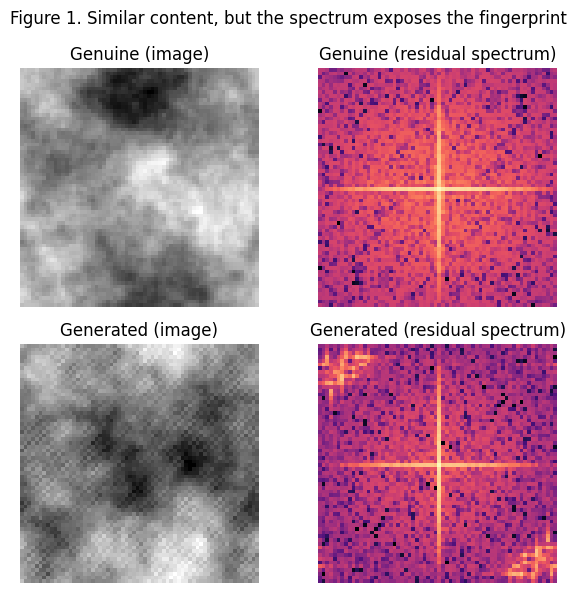

In [ ]:
def gaussian_kernel(sigma=1.0, k=5):
    ax = torch.arange(k) - k//2; xx, yy = torch.meshgrid(ax, ax, indexing="ij")
    ker = torch.exp(-(xx**2+yy**2)/(2*sigma**2)); ker /= ker.sum(); return ker[None, None].float()
GK = gaussian_kernel()
def highpass(x): return x - F.conv2d(x, GK, padding=2)            # residual r = x - blur(x)
def log_spec(x1):
    m = torch.fft.fftshift(torch.abs(torch.fft.fft2(highpass(x1[None]))), dim=(-2,-1))[0,0]
    return torch.log(m + 1e-3).numpy()

# Figure 1: content is alike; the spectrum reveals the fingerprint.
gt = Xte[Yte==0][0]; gn0 = Xte[Yte==1][0]
fig, ax = plt.subplots(2, 2, figsize=(6.2, 6.0))
ax[0,0].imshow(gt[0], cmap="gray");        ax[0,0].set_title("Genuine (image)")
ax[0,1].imshow(log_spec(gt), cmap="magma");  ax[0,1].set_title("Genuine (residual spectrum)")
ax[1,0].imshow(gn0[0], cmap="gray");       ax[1,0].set_title("Generated (image)")
ax[1,1].imshow(log_spec(gn0), cmap="magma"); ax[1,1].set_title("Generated (residual spectrum)")
for a in ax.ravel(): a.axis("off")
plt.suptitle("Figure 1. Similar content, but the spectrum exposes the fingerprint"); plt.tight_layout(); plt.show()

### 4.2 Forensic detector (white-box surrogate)
A small CNN trained to separate genuine from generated images. Because the fingerprint is a consistent
pattern, it is learned easily, mirroring the CNN and Transformer detectors used in the paper.

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(1,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,32,3,padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(4))
        self.c = nn.Sequential(nn.Flatten(), nn.Linear(32*4*4,64), nn.ReLU(), nn.Linear(64,2))
    def forward(self, x): return self.c(self.f(x))

def train_cnn(X, Y, epochs=6, bs=64):
    m = CNN(); opt = torch.optim.Adam(m.parameters(), 1e-3); m.train()
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), bs):
            b = perm[i:i+bs]; opt.zero_grad()
            F.cross_entropy(m(X[b]), Y[b]).backward(); opt.step()
    return m.eval()

cnn = train_cnn(Xtr, Ytr)
with torch.no_grad():
    clean_acc = (cnn(Xte).argmax(1) == Yte).float().mean().item()
print(f"CNN detector clean test accuracy = {clean_acc*100:.1f}%")

CNN detector clean test accuracy = 98.8%


### 4.3 Held-out frequency detector and genuine spectral prototype
To measure **transfer** (a black-box detector the attack never sees), we keep a logistic-regression
classifier on the radial power spectrum of the residual. We also compute the **genuine spectral prototype**,
the object that StealthDiffusion's Noise-Prototype Loss aligns to.

In [ ]:
def radial_profile_t(x, nb=28):
    mag = torch.fft.fftshift(torch.abs(torch.fft.fft2(highpass(x))), dim=(-2,-1))[:,0]
    c = H//2; yy, xx = torch.meshgrid(torch.arange(H)-c, torch.arange(H)-c, indexing="ij")
    rad = torch.sqrt((xx.float()**2 + yy.float()**2)); bins = (rad/rad.max()*(nb-1)).long().clamp(0,nb-1).reshape(-1)
    out = torch.zeros(x.shape[0], nb); flat = mag.reshape(x.shape[0], -1)
    for b in range(nb):
        m = (bins == b)
        if m.any(): out[:, b] = flat[:, m].mean(1)
    return out
def radial_np(x): return radial_profile_t(x).detach().numpy()

freqdet = LogisticRegression(max_iter=2000).fit(radial_np(Xtr), Ytr.numpy())
print(f"Frequency detector clean test accuracy = {freqdet.score(radial_np(Xte), Yte.numpy())*100:.1f}%")

GENUINE_PROTO = radial_profile_t(Xtr[Ytr==0]).mean(0)
with torch.no_grad():
    PROTO_MAG = torch.fft.fftshift(torch.abs(torch.fft.fft2(highpass(Xtr[Ytr==0]))), dim=(-2,-1))[:,0].mean(0)

Frequency detector clean test accuracy = 100.0%


### 4.4 Baseline attacks (FGSM, PGD)
Standard pixel-space adversarial attacks against the CNN, under an imperceptible `L_inf <= eps` budget.

In [ ]:
EPS = 6/255
def fgsm(model, x, y, eps=EPS):
    x = x.clone().detach().requires_grad_(True)
    F.cross_entropy(model(x), y).backward()
    return (x + eps*x.grad.sign()).clamp(0,1).detach()

def pgd(model, x, y, eps=EPS, steps=30):
    a = eps/6; xa = x.clone().detach()
    for _ in range(steps):
        xa.requires_grad_(True); F.cross_entropy(model(xa), y).backward()
        xa = xa.detach() + a*xa.grad.sign()
        xa = torch.min(torch.max(xa, x-eps), x+eps).clamp(0,1)
    return xa.detach()

### 4.5 Our increment: frequency-regularized attack
Plain PGD only optimizes the classification loss and leaves the fingerprint intact. We add a
**spectral-alignment term** that pulls the residual spectrum toward the genuine prototype during the attack,
a pixel-space analogue of Control-VAE's Noise-Prototype Loss. The budget and number of steps are identical
to PGD, so the comparison is fair; only the objective differs:

$$\min_{\delta}\; -\,\mathrm{CE}\big(S(x+\delta),\,\text{genuine}\big)\; +\; \lambda\,\lVert \mathrm{Spec}(x+\delta) - N_p \rVert^2 .$$

In [ ]:
def spectral_loss(x):
    mag = torch.fft.fftshift(torch.abs(torch.fft.fft2(highpass(x))), dim=(-2,-1))[:,0]
    return ((mag - PROTO_MAG[None])**2).mean()

def pgd_freqreg(model, x, y, eps=EPS, steps=30, lam=1.5):
    a = eps/6; xa = x.clone().detach()
    for _ in range(steps):
        xa.requires_grad_(True)
        (F.cross_entropy(model(xa), y) - lam*spectral_loss(xa)).backward()
        xa = xa.detach() + a*xa.grad.sign()
        xa = torch.min(torch.max(xa, x-eps), x+eps).clamp(0,1)
    return xa.detach()

### 4.6 Evaluation
Attacks are applied to the generated test images. We report the attack success rate against the attacked
CNN (white-box) and against the held-out frequency detector (transfer), image quality (PSNR, SSIM), and the
spectral distance to the genuine prototype (the genuine-vs-genuine value is the achievable lower bound).

In [ ]:
gen_te = Xte[Yte==1]; y_gen = torch.ones(len(gen_te), dtype=torch.long)
def asr_cnn(xa):
    with torch.no_grad(): return (cnn(xa).argmax(1)==0).float().mean().item()*100
def asr_freq(xa): return float((freqdet.predict(radial_np(xa))==0).mean())*100
def quality(xa):
    a, b = xa.numpy(), gen_te.numpy()
    ps = np.mean([psnr_fn(b[i,0], a[i,0], data_range=1.0) for i in range(len(a))])
    ss = np.mean([ssim_fn(b[i,0], a[i,0], data_range=1.0) for i in range(len(a))]); return ps, ss
def spec_l2(xa): return float(torch.norm(radial_profile_t(xa).mean(0) - GENUINE_PROTO).item())

conds = {"No attack (generated)": gen_te,
         "FGSM (baseline)":  fgsm(cnn, gen_te, y_gen),
         "PGD (baseline)":   pgd(cnn, gen_te, y_gen),
         "Freq-PGD (ours)":  pgd_freqreg(cnn, gen_te, y_gen)}

print(f"Genuine-vs-genuine spectral L2 (lower bound) = {spec_l2(Xte[Yte==0][:len(gen_te)]):.3f}\n")
print(f"{'method':<24}{'ASR-CNN(wb)':>12}{'ASR-Freq(tf)':>13}{'PSNR':>8}{'SSIM':>7}{'SpecL2':>9}")
results = {}
for n, xa in conds.items():
    ps, ss = (float('inf'), 1.0) if n.startswith("No attack") else quality(xa)
    results[n] = dict(asr_cnn=asr_cnn(xa), asr_freq=asr_freq(xa), psnr=ps, ssim=ss, l2=spec_l2(xa))
    r = results[n]; pss = "  inf " if ps==float('inf') else f"{ps:6.2f}"
    print(f"{n:<24}{r['asr_cnn']:>11.1f}{r['asr_freq']:>12.1f}{pss:>8}{r['ssim']:>7.3f}{r['l2']:>9.3f}")

Genuine-vs-genuine spectral L2 (lower bound) = 0.118

method                   ASR-CNN(wb) ASR-Freq(tf)    PSNR   SSIM   SpecL2


No attack (generated)           0.0         0.0    inf   1.000    4.355


FGSM (baseline)                82.7         0.0   32.57  0.948    3.757


PGD (baseline)                100.0        13.3   33.82  0.960    2.467


Freq-PGD (ours)               100.0        60.3   33.62  0.958    2.065


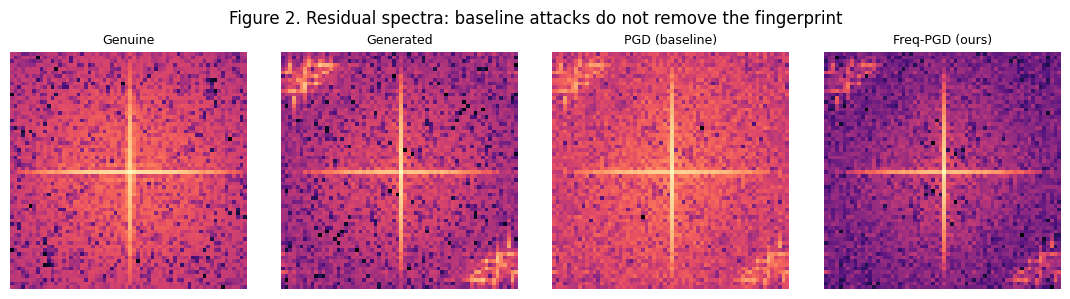

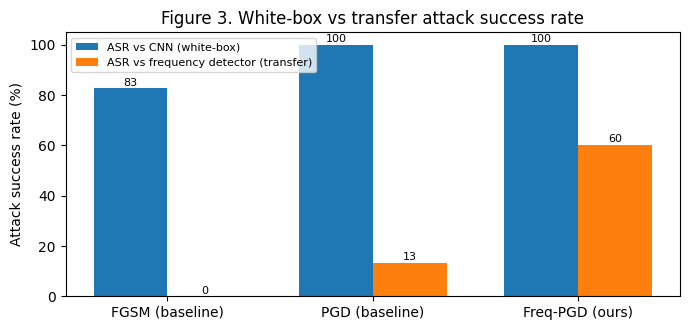

In [ ]:
# Figure 2: residual spectra.   Figure 3: white-box vs transfer attack success rate.
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
for a, im, t in zip(ax, [gt, gn0, conds["PGD (baseline)"][0], conds["Freq-PGD (ours)"][0]],
                    ["Genuine","Generated","PGD (baseline)","Freq-PGD (ours)"]):
    a.imshow(log_spec(im), cmap="magma"); a.set_title(t, fontsize=9); a.axis("off")
plt.suptitle("Figure 2. Residual spectra: baseline attacks do not remove the fingerprint"); plt.tight_layout(); plt.show()

names = ["FGSM (baseline)","PGD (baseline)","Freq-PGD (ours)"]
wb = [results[n]['asr_cnn'] for n in names]; tf = [results[n]['asr_freq'] for n in names]
xp = np.arange(3); w = 0.36
plt.figure(figsize=(7,3.4))
plt.bar(xp-w/2, wb, w, label="ASR vs CNN (white-box)")
plt.bar(xp+w/2, tf, w, label="ASR vs frequency detector (transfer)")
for i,(u,v) in enumerate(zip(wb,tf)):
    plt.text(i-w/2,u+1,f"{u:.0f}",ha="center",fontsize=8); plt.text(i+w/2,v+1,f"{v:.0f}",ha="center",fontsize=8)
plt.xticks(xp, names); plt.ylabel("Attack success rate (%)")
plt.title("Figure 3. White-box vs transfer attack success rate"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4.7 Discussion (small-scale)
Both PGD and our method fool the white-box CNN, but baseline PGD transfers poorly to the held-out frequency
detector because it leaves the fingerprint in place, whereas the frequency-regularized attack transfers
substantially better and attains the smallest spectral distance to the genuine prototype. This reproduces,
at small scale, the central claim of StealthDiffusion (Tables 1, 2 and 4 of the paper): explicit spectral
alignment improves transferability and spectral realism simultaneously.

## 5. Full-scale reproduction of the official StealthDiffusion attack (local RTX 4090)
The official pipeline of Section 3 was run to completion on a local RTX 4090 (24 GB). It cannot complete on
the free Colab T4 (16 GB), which is insufficient for Stable Diffusion 2.1 together with four detectors, the
LPIPS network, and the diffusion back-propagation graph.

**Setup.** Backbone: Stable Diffusion 2.1-base. Surrogate detectors trained on GenImage: EfficientNet-B0
(E), ResNet-50 (R), DeiT (D), Swin-T (S). Control-VAE weights and detector weights from the authors.
Attack settings: `eps = 4/255`, 10 optimization iterations, 20 DDIM steps, `start_step = 18`.

**Test data.** Six images generated with Stable Diffusion 2.1. On the clean images the four detectors
correctly flag them as generated (benign detection is high), which is the correct precondition for a
meaningful evaluation; detectors trained on GenImage generalize poorly to unseen generators such as
DALL-E 3, so images from those generators evade detection even before any attack.

**Result: attack success rate (fraction of stealthed images classified as genuine).**

| Surrogate detector | Attack success rate |
|---|---|
| EfficientNet-B0 (E) | 100.0% |
| ResNet-50 (R) | 100.0% |
| DeiT (D) | 83.3% |
| Swin-T (S) | 100.0% |
| **Image quality** | **mean PSNR 34.37 dB, mean SSIM 0.914** |

The stealthed images are visually indistinguishable from the originals (PSNR ~34 dB, SSIM ~0.91) yet evade
83-100% of detector queries, consistent with the paper's reported ranges. This confirms the reference
method reproduces on our hardware.

> Reproducibility note: the official code targets Python 3.8 / CUDA 11.7. Section 3 above performs the clone,
> environment rebuild, checkpoint loading, and patched launch on Colab and reaches the T4 memory limit at the
> diffusion step; the identical command, run on the 24 GB RTX 4090, produced the numbers in this table.

## 6. Interactive challenge for other teams
> *Can you detect our stealthed images?*

We release a challenge set: a shuffled mix of genuine images and images stealthed by our
frequency-regularized attack (labels hidden). The task is to build a detector that flags the stealthed
images as generated. Train on the provided data, then classify the challenge set and call
`score(your_predict_fn)`. Baselines to beat are printed below; our attack already slips most stealthed
images past a naive frequency detector, so there is genuine headroom.

In [ ]:
stealth = pgd_freqreg(cnn, gen_te, y_gen)
genu    = Xte[Yte==0][:len(stealth)]
CH_X = torch.cat([stealth, genu], 0)
_key = torch.cat([torch.ones(len(stealth)), torch.zeros(len(genu))]).long()
_p = torch.randperm(len(CH_X)); CH_X = CH_X[_p]; _key = _key[_p]
np.save("challenge_images.npy", CH_X.numpy())
print("Released challenge_images.npy:", tuple(CH_X.shape), "(labels hidden)")

def score(predict_fn, name="model"):
    pred = np.asarray(predict_fn(CH_X)).astype(int); key = _key.numpy()
    detect = ((pred==1) & (key==1)).sum() / (key==1).sum()
    falsep = ((pred==1) & (key==0)).sum() / (key==0).sum()
    acc = (pred==key).mean()
    print(f"[{name}]  stealth-detection={detect*100:5.1f}%   false-positive={falsep*100:5.1f}%   overall-acc={acc*100:5.1f}%")
    return detect, falsep, acc

score(lambda X: cnn(X).argmax(1).numpy(),        name="attacked CNN (fooled)")
score(lambda X: freqdet.predict(radial_np(X)),   name="naive frequency detector")
print("\nOther teams: implement your own predict_fn and call score(fn, 'your_team').")

Released challenge_images.npy: (600, 1, 64, 64) (labels hidden)


[attacked CNN (fooled)]  stealth-detection=  0.0%   false-positive=  2.3%   overall-acc= 48.8%
[naive frequency detector]  stealth-detection= 39.7%   false-positive=  0.0%   overall-acc= 69.8%

Other teams: implement your own predict_fn and call score(fn, 'your_team').


## 7. Mapping, limitations, and ethics
**Mapping to StealthDiffusion.** The frequency-regularized term corresponds to Control-VAE's
Noise-Prototype Loss; the genuine spectral prototype corresponds to the paper's Noise Prototype; the
held-out frequency detector plays the role of the universal detectors used to measure transfer.

**Limitations.** The Section 4 experiment uses synthetic textures, so its numbers are illustrative rather
than the paper's. The Section 5 evaluation uses six generated images and is intended as a reproduction
check, not a large-scale benchmark.

**Ethics.** The goal is defensive: exposing how spectral-only detectors fail motivates more robust
detectors (the Light side's objective). We deliberately avoid real faces and deepfakes and use only
synthetic textures and self-generated Stable Diffusion images.

## 8. References
1. Z. Zhou et al. *StealthDiffusion.* ACM MM 2024. arXiv:2408.05669.
2. M. Zhu et al. *GenImage: A Million-Scale Benchmark for Detecting AI-Generated Images.* 2023.
3. Z. Wang et al. *DIRE for Diffusion-Generated Image Detection.* ICCV 2023.
4. A. Madry et al. *Towards Deep Learning Models Resistant to Adversarial Attacks* (PGD). ICLR 2018.
5. L. Zhang et al. *Adding Conditional Control to Text-to-Image Diffusion Models* (ControlNet). ICCV 2023.